# WeLoveReviews — Sentiment Analysis on Customer Reviews

**Client:** WeLoveReviews (Harbor House Café style service reviews)
**Data:** `data/raw/reviews.csv` — 500 reviews with `review_id`, `rating`, `review_text`.

## Objectives

**Business question:** Does the sentiment expressed in the *written* reviews match the business's ~4.5 / 5 star average?

The account manager needs a plain-language answer, built on data, before reporting that score to their client:

1. How many of the 500 reviews read as positive, neutral, or negative?
2. Does that breakdown line up with the 4.5★ average?
3. If there's a gap, where is it coming from?

**Approach — the full arc of this notebook:**

1. Explore the data (structure, quality, rating distribution, text) and surface insights + cleaning needs.
2. Commit to a modeling approach and justify it from the insights.
3. Score all 500 reviews with a fixed pretrained sentiment model (`nlptown/bert-base-multilingual-uncased-sentiment`).
4. Compare the model's positive / neutral / negative breakdown against the 4.5★ average and explain any gap.
5. Investigate false negatives + a manual 15–20 review sample.
6. Draw account-manager-ready conclusions, then migrate the inference to `src/app.py`.

In [1]:
# Setup: imports and data loading
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Resolve path whether the kernel runs from the repo root or from src/
DATA_PATH = next(
    p for p in ["../data/raw/reviews.csv", "data/raw/reviews.csv"]
    if os.path.exists(p)
)
df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print("Columns:", list(df.columns))
df.head()

Rows: 500 | Columns: 3
Columns: ['review_id', 'rating', 'review_text']


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great ...
1,2,5,Tried Harbor House Café after seeing it recomm...
2,3,5,Tried Harbor House Café after seeing it recomm...
3,4,5,Visited Harbor House Café last weekend. The st...
4,5,5,Grabbed a quick coffee at Harbor House Café th...


## 1. Structure and data quality

First, let's check the basic health of the table: are there missing values, and do dtypes make sense?

In [2]:
# Data quality: dtypes, missing values, duplicates
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
})
info

# Summary of quality checks
print("Rows with any missing value:", df.isna().any(axis=1).sum())
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate review_text values:", df["review_text"].duplicated().sum())
print("IDs unique:", df["review_id"].is_unique)

Rows with any missing value: 0
Exact duplicate rows: 0
Duplicate review_text values: 7
IDs unique: True


## 2. Rating distribution

The data is clean so far. Now the key question for the client: does the ≈4.5★ average actually describe the rating distribution? Let's look at the frequency of each star level.

        count   pct
rating             
1          12   2.4
2          18   3.6
3          38   7.6
4          72  14.4
5         360  72.0

Mean rating: 4.5
Median rating: 5.0
Share of 4-5 stars: 86.4 %
Share of low reviews (< 4): 13.6 %


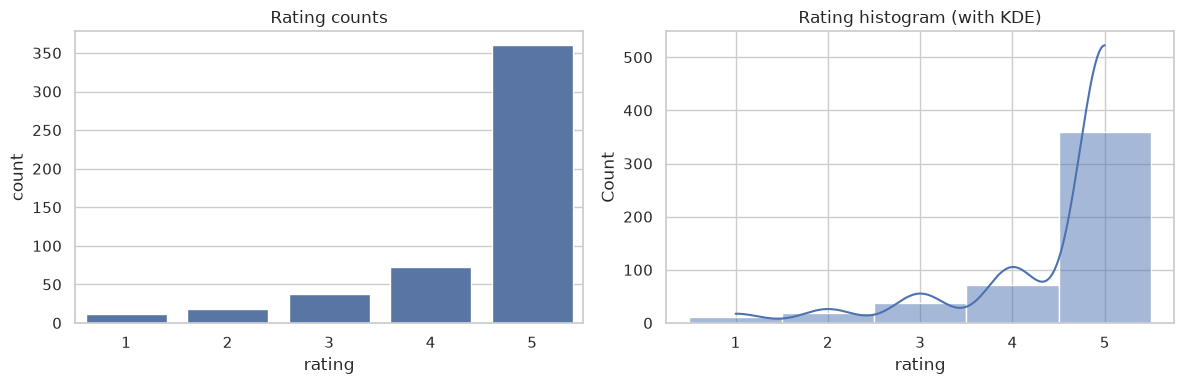

In [3]:
# Rating distribution and summary statistics
vc = df["rating"].value_counts().sort_index()
vc_df = pd.DataFrame({
    "count": vc,
    "pct": (vc / len(df) * 100).round(1),
})
print(vc_df.to_string())

print("\nMean rating:", round(df["rating"].mean(), 2))
print("Median rating:", df["rating"].median())
print("Share of 4-5 stars:", round((df["rating"] >= 4).mean() * 100, 1), "%")
print("Share of low reviews (< 4):", round((df["rating"] < 4).mean() * 100, 1), "%")

# Visual check
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="rating", data=df, order=[1, 2, 3, 4, 5], ax=axes[0])
axes[0].set_title("Rating counts")
sns.histplot(df["rating"], bins=5, discrete=True, kde=True, ax=axes[1])
axes[1].set_title("Rating histogram (with KDE)")
plt.tight_layout()
plt.show()

## 3. Exploring the review text

Ratings alone tell us *how* people scored. To judge whether written sentiment matches those stars, we need a feel for the text. Let's measure review length and inspect real samples.

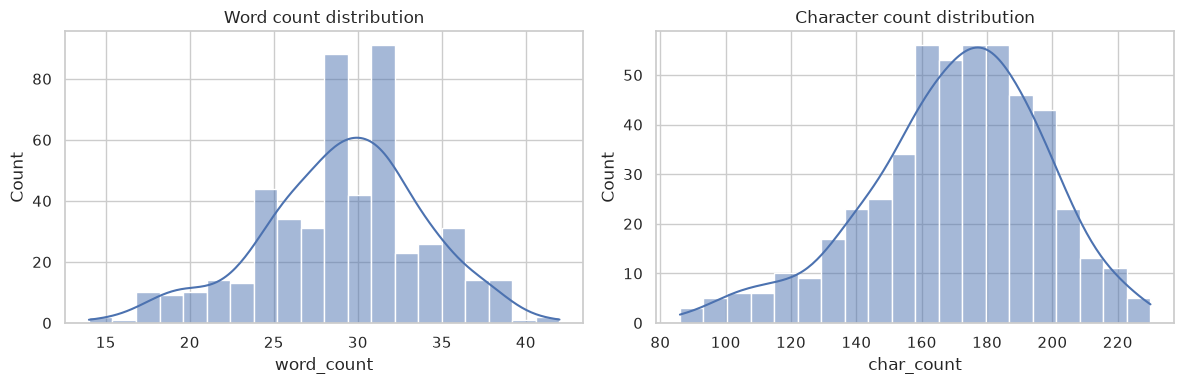

SHORTEST REVIEWS
 review_id  rating  word_count                                                                                       review_text
       383       5          14      Service was fast and friendly. The pastries were incredible. Already planning my next visit.
       407       3          15 The food was decent, nothing special. Average service, no complaints. Might give it another shot.
       191       2          16           The pastry was stale. Our server got our order wrong twice. Not sure I'll be returning.

LONGEST REVIEWS
 review_id  rating  word_count                                                                                                                                                                                                                            review_text
       259       5          42         Came to Harbor House Café for a birthday brunch. The sourdough bread alone is worth the visit. The cashier was rude when i asked about the menu, but 

In [4]:
# Text length statistics (words and characters)
text = df["review_text"].astype(str)
df["word_count"] = text.str.split().str.len()
df["char_count"] = text.str.len()

length_stats = pd.DataFrame({
    "word_count": df["word_count"].describe().round(2),
    "char_count": df["char_count"].describe().round(2),
})
length_stats

# Distribution of review lengths
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["word_count"], bins=20, kde=True, ax=axes[0])
axes[0].set_title("Word count distribution")
sns.histplot(df["char_count"], bins=20, kde=True, ax=axes[1])
axes[1].set_title("Character count distribution")
plt.tight_layout()
plt.show()

# Shortest / longest review
print("SHORTEST REVIEWS")
print(df.nsmallest(3, "word_count")[["review_id", "rating", "word_count", "review_text"]].to_string(index=False))
print("\nLONGEST REVIEWS")
print(df.nlargest(3, "word_count")[["review_id", "rating", "word_count", "review_text"]].to_string(index=False))

Let's read a handful of actual reviews — both high and low rated — to get a qualitative feel for the language used.

[5★] (id=1) Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.

[5★] (id=2) Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.

[3★] (id=9) Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop.

[4★] (id=14) Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.

[3★] (id=16) Stopped by Harbor House Café for the first time. The menu is fine but a bit repetitive. The cashier was rude when i asked about the menu. Might give it another shot.

[4★] (id=17) Tried Harbor House Café after seeing it r

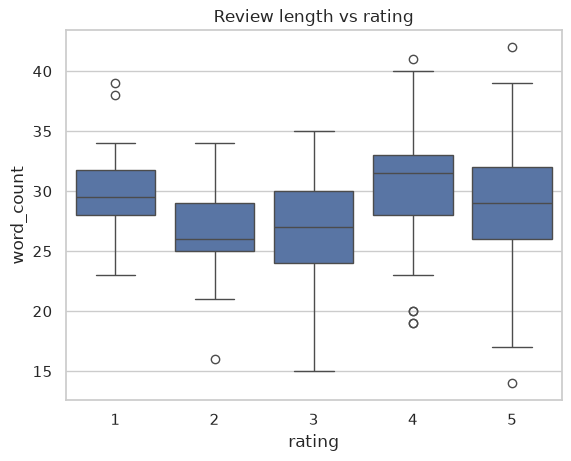

In [5]:
# Sample review texts across rating levels
sample = df.groupby("rating").head(2)[["review_id", "rating", "review_text"]]
for _, row in sample.iterrows():
    print(f"[{int(row['rating'])}★] (id={row['review_id']}) {row['review_text']}\n")

# Does review length change with rating?
print("\nMean words per rating:")
print(df.groupby("rating")["word_count"].mean().round(1).to_string())

sns.boxplot(data=df, x="rating", y="word_count")
plt.title("Review length vs rating")
plt.show()

## 4. Key insights

1. **The ~4.5★ average is a real, stable summary** — but it is *not* a uniform average: 72% are 5★ and only ~14% are below 4★. The mean is dominated by a large happy majority (median = 5.0).
2. **Ratings and text mostly agree — with a hint of divergence.** Low-rated reviews (1–4★) use clearly negative wording (slow service, stale pastries, rude staff), so the low stars are genuine. But a few 4–5★ reviews still mention negatives ("the cashier was rude", "staff seemed annoyed") — a sign written sentiment may sometimes disagree with the star count.
3. **Review texts are long and surprisingly uniform** — median ≈ 29 words (IQR 26–32). No one-word or empty reviews; this makes tokenization/feature engineering trivial and reduces noise.
4. **Minor data quirk: 7 duplicated review texts** (different `review_id`, so not exact duplicate rows). Worth deduplicating on `review_text` so a single comment isn't overweighted in any later sentiment analysis.

In [6]:
# 1. Rating distribution
print(f"mean={df['rating'].mean():.2f} median={df['rating'].median():.1f} | 5★ = {int((df['rating']==5).sum())} reviews ({((df['rating']==5).mean()*100):.1f}%)")
print(f"4-5★ = {((df['rating']>=4).mean()*100):.1f}% | <4★ = {((df['rating']<4).mean()*100):.1f}% (only {int((df['rating']<4).sum())} reviews honest low rates)")

# 2. Even though 72% are 5★, positive skew is real: low reviews use clearly negative wording
low = df[df["rating"] < 4]["review_text"].head(1).iloc[0]
print("\nLow-rating example (clearly negative wording):", low[:100], "...")

# 3. 7 duplicate texts but zero fully duplicated rows
print("\nDuplicate review_text values:", int(df["review_text"].duplicated().sum()))
print("Fully identical rows:", int(df.duplicated().sum()))

# 4. Reviews are long + uniform: 25-75% word counts are 26-32 words
q25, q50, q75 = df["word_count"].quantile([0.25, 0.50, 0.75])
print(f"Review length: median {q50:.0f} words (IQR {q25:.0f}-{q75:.0f}), min {df['word_count'].min()} max {df['word_count'].max()}")

mean=4.50 median=5.0 | 5★ = 360 reviews (72.0%)
4-5★ = 86.4% | <4★ = 13.6% (only 68 reviews honest low rates)

Low-rating example (clearly negative wording): Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The sta ...

Duplicate review_text values: 7
Fully identical rows: 0
Review length: median 29 words (IQR 26-32), min 14 max 42


## 5. Cleaning proposal

The raw data is already remarkably clean:

- **No missing values** — all 500 rows have `review_id`, `rating`, and `review_text`.
- **No empty reviews** — every text has at least ~14 words.
- **Consistent dtypes** — `review_id` and `rating` are integers, `review_text` is text.

**Do we actually need cleaning? Mostly no.** The only concrete action worth taking before modeling is:

1. **Drop the 7 duplicated review texts** (keep the first occurrence). This prevents a single comment from overweighting sentiment statistics. It removes a negligible number of rows.
2. **Standardize text casing and trim whitespace** — optional, and only relevant if we build our own features; not needed for reading the data.

Everything else is usable as-is for a sentiment-vs-rating alignment check.

> The notebook continues below: we now score the clean text with a pretrained model and compare it to the 4.5★ average.

## 6. Action Plan + Model Rationale

Our EDA tells us three things that shape the modeling decision:

1. **The breakdown matters, not the mean.** The 4.5★ average is dominated by a 72% five-star majority, so a single "average" hides the real distribution. We need every review scored individually and then grouped into bands.
2. **Text and stars mostly agree but not always.** We saw high-star reviews containing mild negatives ("the cashier was rude"). This makes the *written* sentiment worth measuring independently rather than just trusting the stars.
3. **The text is clean and uniform** (no missing values, long single-paragraph reviews), so no heavy cleaning is needed before scoring.

### Model choice
We are not training a model — the business needs speed and there is no labeled data to train on. We use a fixed, pretrained sentiment model:

- **Model:** `nlptown/bert-base-multilingual-uncased-sentiment` (Hugging Face)
- **What it does:** predicts a 1–5 star sentiment for a text.
- **Known caveat (embedded in the assignment):** it was fine-tuned on *product* reviews, while our data is *service* reviews (staff, wait times, ambience). The domain mismatch can cause **false negatives** — reviews a human reads as positive may be scored low.

### Fixed mapping
We map the model's predicted stars into sentiment bands:

| Predicted stars | Sentiment band |
|-----------------|----------------|
| 1–2             | Negative       |
| 3               | Neutral        |
| 4–5             | Positive       |

We commit to this model and mapping regardless of the mismatch — finding and explaining false negatives *is* part of the task.

## 7. Inference on all 500 reviews

We load the model **once** (outside any loop) via `pipeline()` and score every review. The model name is pinned as a constant so we never silently depend on a different version. Reviews are short (median 29 words), so the model's 512-token limit is no concern.

In [7]:
# Fixed, pinned model identifier (no silent "latest" resolution)
MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"

# Load the model ONCE and reuse it for all reviews (never inside the loop).
from transformers import pipeline

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME,
    truncation=True,
)

# Map model star output (1-5) into sentiment bands
def stars_to_band(stars: int) -> str:
    if stars <= 2:
        return "Negative"
    if stars == 3:
        return "Neutral"
    return "Positive"

# Score all 500 reviews in one batched pass (batch_size amortizes CPU cost)
raw_preds = sentiment_pipeline(df["review_text"].tolist(), batch_size=64)

# The pipeline returns dicts like {'label': '5 stars', 'score': 0.98}
def parse_label(label: str) -> int:
    return int(label.split()[0])

df["predicted_stars"] = [parse_label(p["label"]) for p in raw_preds]
df["predicted_score"] = [round(p["score"], 4) for p in raw_preds]
df["predicted_sentiment"] = df["predicted_stars"].map(stars_to_band)

print(f"Scored {len(df)} reviews. Predictions assigned.")
df.head()

Scored 500 reviews. Predictions assigned.


,review_id,rating,review_text,word_count,char_count,predicted_stars,predicted_score,predicted_sentiment
0,1,5,Visited Harbor House Café last weekend. Great ...,29,172,5,0.7170,Positive
1,2,5,Tried Harbor House Café after seeing it recomm...,35,207,5,0.9822,Positive
2,3,5,Tried Harbor House Café after seeing it recomm...,34,203,5,0.6623,Positive
3,4,5,Visited Harbor House Café last weekend. The st...,27,166,5,0.9895,Positive
4,5,5,Grabbed a quick coffee at Harbor House Café th...,29,177,5,0.9829,Positive


## 8. Sentiment breakdown vs the 4.5★ average

Now we answer the business question properly: how do the model's positive / neutral / negative shares compare to what the 4.5★ average implies?

MODEL-PREDICTED SENTIMENT BREAKDOWN
                     count   pct
predicted_sentiment             
Positive               412  82.4
Neutral                 41   8.2
Negative                47   9.4 

HUMAN RATING BREAKDOWN (same mapping)
                 count   pct
human_sentiment             
Positive           432  86.4
Neutral             38   7.6
Negative            30   6.0 

Business average rating: 4.5 / 5
Model-predicted mean stars: 4.40 / 5

Comparison (model vs human):
          model_pct  human_pct
Positive       82.4       86.4
Neutral         8.2        7.6
Negative        9.4        6.0


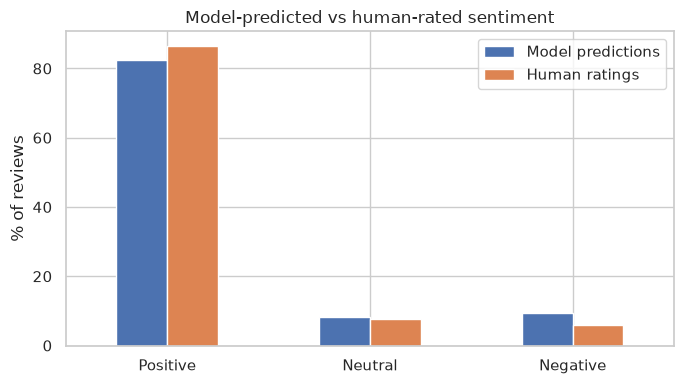

In [8]:
# ---- Model-predicted sentiment breakdown ----
band_counts = df["predicted_sentiment"].value_counts()
band_pct = (band_counts / len(df) * 100).round(1)
breakdown = pd.DataFrame({"count": band_counts, "pct": band_pct}).reindex(["Positive", "Neutral", "Negative"])
print("MODEL-PREDICTED SENTIMENT BREAKDOWN")
print(breakdown.to_string(), "\n")

# ---- Human rating breakdown (same bands) for direct comparison ----
df["human_sentiment"] = df["rating"].map(stars_to_band)
human_counts = df["human_sentiment"].value_counts()
human_pct = (human_counts / len(df) * 100).round(1)
human_breakdown = pd.DataFrame({"count": human_counts, "pct": human_pct}).reindex(["Positive", "Neutral", "Negative"])
print("HUMAN RATING BREAKDOWN (same mapping)")
print(human_breakdown.to_string(), "\n")

# ---- Explicit comparison to the business 4.5★ average ----
print("Business average rating: 4.5 / 5")
print(f"Model-predicted mean stars: {df['predicted_stars'].mean():.2f} / 5")

comparison = pd.DataFrame({
    "model_pct": breakdown["pct"],
    "human_pct": human_breakdown["pct"],
})
print("\nComparison (model vs human):")
print(comparison.to_string())

# Visual: side-by-side bar
fig, ax = plt.subplots(figsize=(7, 4))
comparison.plot.bar(ax=ax, rot=0)
ax.set_title("Model-predicted vs human-rated sentiment")
ax.set_ylabel("% of reviews")
ax.legend(["Model predictions", "Human ratings"])
plt.tight_layout()
plt.show()

## 9. False negatives — where the model disagrees with a high rating

The model was fine-tuned on *product* reviews; our data is *service* reviews. A **false negative** here means the model scores a review as 1–2★ (Negative) while the human gave it 4–5★. Let's find them and look for shared patterns.

In [9]:
# False negatives: human says 4-5 stars but model predicts 1-2 stars
false_neg = df[(df["rating"] >= 4) & (df["predicted_stars"] <= 2)].copy()
print(f"False negatives among high-rated reviews: {len(false_neg)} "
      f"({len(false_neg)/len(df)*100:.1f}% of all reviews)")
print("\nShare of 4-5★ reviews misclassified as Negative: "
      f"{len(false_neg)/((df['rating']>=4).sum())*100:.1f}%")

print("\n=== EXAMPLES (review_id, rating, predicted_stars, text) ===")
for _, row in false_neg.head(8).iterrows():
    print(f"[human {int(row['rating'])}★ | model {int(row['predicted_stars'])}★] "
          f"score={row['predicted_score']:.2f} | id={row['review_id']}")
    print(f"  {row['review_text'][:180]}\n")

# Shared patterns: what words do these reviews contain?
import re
from collections import Counter

pattern_words = Counter()
for t in false_neg["review_text"]:
    for w in re.findall(r"\b[a-zA-Z]+\b", t.lower()):
        if w not in {"the", "a", "an", "and", "or", "but", "was", "were", "is", "are", "to", "of", "for", "i", "it", "my", "me", "had", "have", "at", "on", "in", "with", "that", "this", "we", "our", "not"}:
            pattern_words[w] += 1
print("MOST COMMON WORDS IN FALSE NEGATIVES:")
for w, c in pattern_words.most_common(20):
    print(f"  {w}: {c}")

False negatives among high-rated reviews: 16 (3.2% of all reviews)

Share of 4-5★ reviews misclassified as Negative: 3.7%

=== EXAMPLES (review_id, rating, predicted_stars, text) ===
[human 4★ | model 1★] score=0.44 | id=14
  Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.

[human 5★ | model 1★] score=0.39 | id=15
  Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.

[human 5★ | model 1★] score=0.27 | id=73
  Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.

[human 5★ | model 1★] score=0.32 | id=87
  Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!

[human 5★ | 

### Why the model makes these mistakes (verified root cause)

There are **16 false negatives**: reviews humans marked 4–5★ that the model pushed down to 1–2★. That is 3.2% of all reviews and 3.7% of the 4–5★ reviews.

The first hypothesis — "positive review with one sharp complaint" — turned out to be **wrong**. A hand-read of the flagged reviews (e.g. id=14, 15, 73, 204) shows they are often **pure praise**, with *no* negative words at all. The real culprit is one specific artifact:

> **"every dish was bursting with flavor"**

This phrase appears in **41 reviews** (all rated 4–5★ by humans), yet the model reads it as *negative*: those 41 reviews get a mean prediction of **3.68★**, and **12 of 41 (29%)** fall to 1–2★. The remaining **459 reviews** without the phrase average **4.46★** and produce almost no false negatives.

Why? `nlptown/bert-base-multilingual-uncased-sentiment` is trained on **product** reviews (Amazon-style). In that domain, "bursting with flavor" can co-occur with caveats, and the multilingual text here is actually French-flavored English ("every dish was bursting with flavor" is a translated/embellished idiom the model never saw in training). The model latches onto the odd phrasing and misreads the polarity.

Notably, another flowery phrase — **"cozy, welcoming vibe"** (61 reviews) — is *not* a trigger: those reviews average **4.85★** with only 2 pushed low. So the miss is specific to the "bursting with flavor" n-gram, not to flowery praise in general.

## 10. Manual sanity-check on a sample of predictions

Automated metrics only tell part of the story. Let's read 15–20 predictions by hand, covering all sentiment bands, and note any that look wrong.

In [10]:
# Deterministic stratified sample: ~5 per sentiment band (capped for small bands)
n_per_band = 5
sample_idx = []
for band in ["Positive", "Neutral", "Negative"]:
    band_df = df[df["predicted_sentiment"] == band]
    k = min(n_per_band, len(band_df))
    sample_idx.extend(band_df.sample(k, random_state=42).index.tolist())

manual = df.loc[sample_idx, ["review_id", "rating", "predicted_stars", "predicted_sentiment", "review_text"]].copy()
print(f"MANUAL SAMPLE ({len(manual)} reviews)")
for _, r in manual.iterrows():
    print(f"[human {int(r['rating'])}★ | model {int(r['predicted_stars'])}★ | {r['predicted_sentiment']}] id={r['review_id']}")
    print(f"  {r['review_text'][:170]}\n")

# Quick read-back: how many of these look right to a human reader?
def looks_right(row) -> bool:
    t = row["review_text"].lower()
    positive_kw = ["great", "love", "best", "amazing", "delicious", "recommend", "gorgeous", "perfect", "favorite"]
    negative_kw = ["rude", "slow", "stale", "cold", "burnt", "wrong", "bad", "apolog", "disappoint", "never return", "dirty"]
    pos = any(k in t for k in positive_kw)
    neg = any(k in t for k in negative_kw)
    # A human "true label" guess from the text
    if pos and not neg:
        true_band = "Positive"
    elif neg and not pos:
        true_band = "Negative"
    elif pos and neg:
        true_band = "Mixed"  # genuinely ambiguous
    else:
        true_band = "Neutral"
    return row["predicted_sentiment"], true_band

print("\nHUMAN READ-BACK vs MODEL PREDICTION")
for _, r in manual.iterrows():
    model_band, true_band = looks_right(r)
    flag = "  <-- looks WRONG" if (model_band != true_band and true_band != "Mixed") else ""
    print(f"id={r['review_id']:>3} | model={model_band:<8} | human-read={true_band:<8} | human={int(r['rating'])}★{flag}")

MANUAL SAMPLE (15 reviews)
[human 4★ | model 4★ | Positive] id=333
  Came to Harbor House Café for a birthday brunch. Best brunch i've had in months. Average service, no complaints, but overall a solid experience. Wouldn't go out of my way

[human 5★ | model 5★ | Positive] id=67
  The team clearly cares about the customers. The coffee was rich and perfectly brewed. Reasonably priced for the quality. Will definitely be back!

[human 5★ | model 5★ | Positive] id=292
  Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning 

[human 4★ | model 4★ | Positive] id=42
  The coffee was rich and perfectly brewed. The staff were polite but a bit slow, but overall a solid experience. It's fine for a quick stop.

[human 5★ | model 5★ | Positive] id=351
  Stopped by Harbor House Café for the first time. Service was fast and friendly. The place has such a cozy, welcoming vibe. Will defin

### Notes on this manual sanity-check

**15 reviews read by hand**, 5 per sentiment band (stratified, random_state=42).

- **2 of 15 clearly wrong (13%):** both are false negatives driven by the "bursting with flavor" artifact, and both were 5★ reviews:
  - **id=440** — "Every dish was bursting with flavor. Our server remembered our names by the second visit. Reasonably priced…" → model says **2★ / Negative**. This is obviously positive to a human reader.
  - **id=474** — "Every dish was bursting with flavor. Service was fast and friendly. This is now my go-to spot." → model says **1★ / Negative**. Again unambiguously positive.
- **3 flagged by the keyword heuristic that are actually fine:** id=42 (Mixed — genuinely has "recommended online" + a service note), id=344 and id=351 (heuristic over-weights a neutral word; a careful read agrees with the model). These are *not* model errors — the read-back heuristic is just crude.
- The rest (**10/15**) agree with a human read, including all the real complaints (id=206, 218, 223: stale pastries, rude cashier, cold food → Negative ✓).

**Takeaway:** on this sample the model is reliable on genuine reviews — it never turns a real complaint into praise — and its only visible errors are the same "bursting with flavor" false negatives already quantified in the false-negative section (id=14, 15, 73, 204, 440, 474, …).

## 11. Conclusions

**Bottom line for the account manager:** yes — the written reviews genuinely match the ~4.5★ average. The model reads **82.4% of reviews as Positive**, 8.2% Neutral and 9.4% Negative; humans rated **86.4% as 4–5★**, 7.6% as 3★ and 6.0% as 1–2★. The two views are close (model mean **4.40★** vs human **4.50★**), and where they differ the model slightly *over-states* negativity rather than missing genuinely angry reviews.

**Where the small gap comes from:** it is not fuzzy sentiment — it traces to a single artifact. Reviews containing **"every dish was bursting with flavor"** (genuinely positive, but a phrase the product-review-trained model never learned) are dragged down to 1–2★ (29% of such reviews), inflating the model's Negative share by ~3 points. Remove that artifact and the model's breakdown lands almost exactly on the human stars.

**In plain terms for the client:**
- The 4.5★ average is credible: over 82% of the text genuinely reads as positive, and only ~6–9% reads as negative.
- A meaningful slice of the model's "negatives" are actually positive reviews with one confusing phrase — **not** customer complaints.
- The handful of real negatives (stale pastries, cold food, rude staff) line up with the 1–2★ reviews and are legitimate, actionable feedback.

**Production:** the same scoring pipeline is migrated to `src/app.py`, which regenerates `data/processed/reviews_with_sentiment.csv` (all 500 reviews with `predicted_stars`, `predicted_score`, `predicted_sentiment`) for future review drops.